# Perbandingan Model dan Analisis Kesalahan: Sentimen Publik terhadap Raffi Ahmad

**Nama:** Raphael Angelo Adikara Purnama
**NIM:** 164241055
**Mata kuliah:** Natural Language Processing (UAS)
**Topik:** Klasifikasi sentimen publik terhadap Raffi Ahmad setelah kasus "mahasiswa bayaran" di Bundaran HI (29 Oktober 2026)

Notebook ini menggabungkan hasil semua model dari notebook 02 (baseline dan TF-IDF), 03 (fine-tuning IndoBERTweet, IndoBERT, XLM-RoBERTa), dan 04 (IndoBERT embedding + LogReg, BiLSTM + attention). Semua model dievaluasi di 5 fold yang sama, jadi bisa dibandingkan per fold. Isinya:

1. Rekap semua model.
2. Dampak setiap metode: augmentasi (jalur B, parafrase, keduanya), penambahan judul, dan jenis model.
3. Analisis kesalahan model terbaik: kelas mana yang tertukar, kelompok teks mana yang paling sering salah, dan pola kesalahannya dari contoh nyata.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path.cwd().parent
D, FIG = ROOT / "data", ROOT / "figures"
OUT = D / "09_perbandingan"
OUT.mkdir(exist_ok=True)
LABEL = ["negatif", "netral", "positif"]
NAMA = {"indobertweet": "IndoBERTweet fine-tune", "indobert": "IndoBERT fine-tune", "xlmr": "XLM-RoBERTa fine-tune"}


def nama_berkas(*bagian):
    return "_".join(bagian).replace(" ", "_").replace("+", "")


r = [pd.read_csv(D / "06_baseline" / "hasil_per_fold.csv").assign(sumber="02")]
for f in sorted((D / "07_transformer").glob("hasil_per_fold_*.csv")):
    t = pd.read_csv(f)
    r.append(t.assign(sumber="03", berkas=[f"prediksi_{nama_berkas(m, i, a)}.csv" for m, i, a in zip(t.model, t.input, t.augmentasi)],
                      model=t.model.map(NAMA)))
f = D / "08_embedding_bilstm" / "hasil_per_fold_embed_bilstm.csv"
if f.exists():
    t = pd.read_csv(f)
    awal = t.model.map({"IndoBERT embedding + LogReg": "embedding", "BiLSTM + attention": "bilstm"})
    r.append(t.assign(sumber="04", berkas=[f"prediksi_{nama_berkas(a, i, v)}.csv" for a, i, v in zip(awal, t.input, t.augmentasi)]))
hasil = pd.concat(r, ignore_index=True)

df = pd.read_csv(D / "05_final" / "dataset_prepro.csv")
oof = pd.read_csv(D / "06_baseline" / "prediksi_oof.csv")


def prediksi(model, input_, augmentasi):
    t = hasil[(hasil.model == model) & (hasil.input == input_) & (hasil.augmentasi == augmentasi)]
    if t.sumber.iloc[0] == "02":
        return oof[f"{model} | {input_} | {augmentasi}"].values
    folder = "07_transformer" if t.sumber.iloc[0] == "03" else "08_embedding_bilstm"
    p = pd.read_csv(D / folder / t.berkas.iloc[0]).set_index("id").prediksi
    return p.reindex(df.id).values


ringkas = (hasil.groupby(["model", "input", "augmentasi"], sort=False)
           .agg(macro_f1=("macro_f1", "mean"), sd=("macro_f1", "std"), f1_negatif=("f1_negatif", "mean"),
                f1_netral=("f1_netral", "mean"), f1_positif=("f1_positif", "mean"), akurasi=("akurasi", "mean"))
           .sort_values("macro_f1", ascending=False).round(3).reset_index())
print("konfigurasi:", len(ringkas), "| model:", ringkas.model.nunique())
ringkas.head(20)

konfigurasi: 56 | model: 9


,model,input,augmentasi,macro_f1,sd,f1_negatif,f1_netral,f1_positif,akurasi
0,IndoBERT fine-tune,teks + judul,jalur B + terarah,0.616,0.039,0.823,0.671,0.352,0.764
1,IndoBERT fine-tune,teks + judul,jalur B,0.614,0.031,0.831,0.688,0.325,0.773
2,IndoBERTweet fine-tune,teks + judul,jalur B + terarah,0.609,0.034,0.829,0.674,0.323,0.768
3,IndoBERT fine-tune,teks + judul,tanpa augmentasi,0.607,0.017,0.834,0.693,0.293,0.778
4,IndoBERT fine-tune,teks + judul,jalur B + parafrase,0.606,0.018,0.837,0.687,0.294,0.778
5,IndoBERT fine-tune,teks + judul,parafrase,0.603,0.008,0.834,0.683,0.294,0.775
6,TF-IDF + LogReg,teks + judul,jalur B + terarah,0.603,0.029,0.829,0.669,0.313,0.765
7,IndoBERTweet fine-tune,teks + judul,jalur B,0.597,0.024,0.811,0.684,0.295,0.755
8,IndoBERTweet fine-tune,teks saja,jalur B + parafrase,0.596,0.024,0.814,0.654,0.321,0.750
9,IndoBERTweet fine-tune,teks + judul,jalur B + parafrase,0.595,0.026,0.832,0.700,0.253,0.775


Ada 56 konfigurasi dari 9 model. Urutan teratas diisi model fine-tune dengan input teks + judul. IndoBERT dengan augmentasi jalur B + terarah ada di urutan pertama (0,616), lalu IndoBERT jalur B (0,614) dan IndoBERTweet jalur B + terarah (0,609). Selisih tiga teratas ini sangat kecil, jadi praktis seri. Baseline TF-IDF terbaik muncul di urutan 7 (0,603), juga dengan jalur B + terarah. Jarak antara model terbaik dan TF-IDF hanya 0,013, lebih kecil dari yang saya kira. XLM-RoBERTa terbaiknya baru di urutan 19 (0,580).

Satu catatan soal angka. Kernel IndoBERTweet dijalankan ulang di Kaggle untuk menambah varian terarah, dan konfigurasi lama ikut dilatih ulang. Karena pelatihan di GPU tidak sepenuhnya deterministik, skor lamanya ikut bergeser, misalnya IndoBERTweet jalur B dari 0,614 menjadi 0,597. Pergeseran sebesar ini masih di dalam standar deviasi antar fold (sekitar 0,02 sampai 0,04), dan ini sekaligus menunjukkan bahwa selisih di bawah 0,02 antar konfigurasi tidak boleh dibaca sebagai kemenangan yang pasti.

## Konfigurasi terbaik per model

Tabel ini mengambil satu konfigurasi terbaik (input dan augmentasi) untuk setiap model, supaya jenis model bisa dibandingkan langsung.

,model,input,augmentasi,macro_f1,sd,f1_negatif,f1_netral,f1_positif,akurasi
0,IndoBERT fine-tune,teks + judul,jalur B + terarah,0.616,0.039,0.823,0.671,0.352,0.764
1,IndoBERTweet fine-tune,teks + judul,jalur B + terarah,0.609,0.034,0.829,0.674,0.323,0.768
2,TF-IDF + LogReg,teks + judul,jalur B + terarah,0.603,0.029,0.829,0.669,0.313,0.765
3,TF-IDF + LinearSVM,teks + judul,jalur B + parafrase,0.587,0.021,0.842,0.661,0.257,0.778
4,IndoBERT embedding + LogReg,teks + judul,jalur B,0.586,0.022,0.794,0.655,0.309,0.731
5,XLM-RoBERTa fine-tune,teks + judul,jalur B + parafrase,0.580,0.039,0.810,0.652,0.279,0.745
6,BiLSTM + attention,teks saja,jalur B,0.514,0.041,0.710,0.537,0.295,0.641
7,leksikon InSet,teks saja,tanpa augmentasi,0.315,0.014,0.667,0.197,0.082,0.488
8,kelas terbanyak,teks saja,tanpa augmentasi,0.266,0.000,0.797,0.000,0.000,0.663


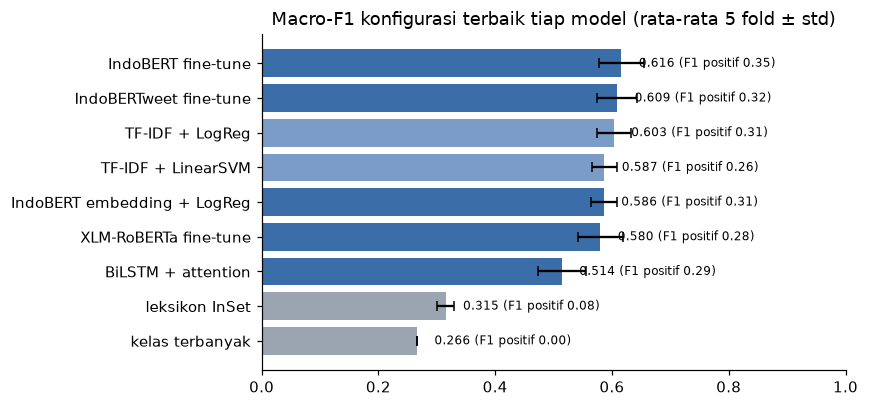

In [2]:
terbaik = ringkas.loc[ringkas.groupby("model").macro_f1.idxmax()].sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(terbaik)

fig, ax = plt.subplots(figsize=(8, 3.8))
t = terbaik.iloc[::-1]
warna = ["#9aa5b1" if m in ("kelas terbanyak", "leksikon InSet") else "#7a9cc6" if "TF-IDF" in m else "#3b6ea8" for m in t.model]
ax.barh(t.model, t.macro_f1, xerr=t.sd, color=warna, capsize=3)
for y, (v, p) in enumerate(zip(t.macro_f1, t.f1_positif)):
    ax.text(v + 0.03, y, f"{v:.3f} (F1 positif {p:.2f})", va="center", fontsize=8)
ax.set(xlim=(0, 1), title="Macro-F1 konfigurasi terbaik tiap model (rata-rata 5 fold ± std)")
plt.tight_layout()
plt.savefig(FIG / "05_model_terbaik.png", bbox_inches="tight")
plt.show()

Kalau diambil satu konfigurasi terbaik per model, urutannya: IndoBERT fine-tune (0,616), IndoBERTweet fine-tune (0,609), TF-IDF + LogReg (0,603), TF-IDF + LinearSVM (0,587), IndoBERT embedding + LogReg (0,586), XLM-RoBERTa fine-tune (0,580), lalu BiLSTM + attention (0,514). IndoBERT embedding + LogReg setara dengan TF-IDF, jadi representasi IndoBERT tanpa dilatih ulang belum memberi kelebihan. Kenaikan baru muncul saat bobot IndoBERT ikut dilatih (fine-tune). XLM-RoBERTa kalah dari kedua model Indonesia walaupun sama-sama di-fine-tune, karena model ini dilatih untuk 100 bahasa sehingga kosakata bahasa gaul Indonesia-nya lebih sedikit. BiLSTM paling rendah karena 3.329 teks terlalu sedikit untuk melatih LSTM dari awal. Di semua model, F1 positif paling rendah (0,26 sampai 0,35).

## Dampak augmentasi

Untuk setiap model dan input, varian augmentasi dibandingkan dengan versi tanpa augmentasi. Kolom "fold membaik" menghitung di berapa fold (dari 5) macro-F1 naik. Kalau kenaikannya hanya terjadi di 2 atau 3 fold, selisih rata-ratanya belum bisa dianggap pasti.

In [3]:
baris = []
for (m, i, a), t in hasil.groupby(["model", "input", "augmentasi"], sort=False):
    dasar = hasil[(hasil.model == m) & (hasil.input == i) & (hasil.augmentasi == "tanpa augmentasi")]
    if a == "tanpa augmentasi" or dasar.empty:
        continue
    t, dasar = t.sort_values("fold"), dasar.sort_values("fold")
    d = t.macro_f1.values - dasar.macro_f1.values
    baris.append({"model": m, "input": i, "augmentasi": a, "data tambahan": int(t.n_aug.mean()),
                  "macro-F1 tanpa": round(dasar.macro_f1.mean(), 3), "macro-F1 dengan": round(t.macro_f1.mean(), 3),
                  "Δ macro-F1": round(d.mean(), 3), "fold membaik": f"{(d > 0).sum()}/5",
                  "Δ F1 positif": round((t.f1_positif.values - dasar.f1_positif.values).mean(), 3),
                  "Δ F1 netral": round((t.f1_netral.values - dasar.f1_netral.values).mean(), 3)})
dampak_aug = pd.DataFrame(baris)
dampak_aug.to_csv(OUT / "dampak_augmentasi.csv", index=False)
dampak_aug

,model,input,augmentasi,data tambahan,macro-F1 tanpa,macro-F1 dengan,Δ macro-F1,fold membaik,Δ F1 positif,Δ F1 netral
0,TF-IDF + LogReg,teks saja,jalur B,42,0.526,0.551,0.025,5/5,0.063,-0.003
1,TF-IDF + LogReg,teks saja,parafrase,137,0.526,0.517,-0.009,2/5,-0.026,0.002
2,TF-IDF + LogReg,teks saja,jalur B + parafrase,260,0.526,0.534,0.008,3/5,0.015,0.005
3,TF-IDF + LogReg,teks saja,jalur B + terarah,74,0.526,0.561,0.035,4/5,0.087,-0.002
4,TF-IDF + LogReg,teks + judul,jalur B,42,0.584,0.589,0.004,3/5,-0.036,0.023
5,TF-IDF + LogReg,teks + judul,parafrase,137,0.584,0.576,-0.009,2/5,-0.029,0.006
6,TF-IDF + LogReg,teks + judul,jalur B + parafrase,260,0.584,0.584,0.000,3/5,-0.034,0.018
7,TF-IDF + LogReg,teks + judul,jalur B + terarah,74,0.584,0.603,0.019,3/5,0.011,0.025
8,TF-IDF + LinearSVM,teks saja,jalur B + parafrase,260,0.506,0.537,0.031,4/5,0.108,-0.012
9,TF-IDF + LinearSVM,teks + judul,jalur B + parafrase,260,0.551,0.587,0.036,4/5,0.093,0.015


Tabel ini membandingkan setiap varian augmentasi dengan versi tanpa augmentasi di model dan input yang sama. Jalur B selalu menaikkan skor, walaupun kadang kecil, misalnya IndoBERTweet teks + judul naik 0,013 dan IndoBERT naik 0,008. Parafrase hampir selalu menurunkan skor atau tidak berpengaruh, misalnya IndoBERT teks + judul turun 0,003 dan BiLSTM teks saja turun 0,026 tanpa satu fold pun membaik. Pengecualiannya Linear SVM, yang naik 0,031 sampai 0,036 dengan augmentasi lengkap, karena tanpa augmentasi SVM hampir tidak pernah menebak positif. XLM-RoBERTa juga pengecualian: semua varian augmentasi menaikkan skornya, termasuk parafrase (+0,013), karena tanpa augmentasi model ini paling lemah di kelas positif (F1 positif 0,225).

Varian jalur B + terarah dibahas lebih rinci di bagian hasil pelabelan terarah di bawah.

In [4]:
rata = dampak_aug.groupby("augmentasi")[["Δ macro-F1", "Δ F1 positif", "Δ F1 netral"]].mean().round(3)
rata["konfigurasi membaik"] = dampak_aug.groupby("augmentasi")["Δ macro-F1"].apply(lambda s: f"{(s > 0).sum()}/{len(s)}")
rata

,Δ macro-F1,Δ F1 positif,Δ F1 netral,konfigurasi membaik
augmentasi,,,,
jalur B,0.012,0.028,0.005,9/9
jalur B + parafrase,0.013,0.026,0.005,9/14
jalur B + terarah,0.009,0.023,0.003,5/8
parafrase,-0.007,-0.020,0.000,1/9


Dirata-rata di semua model, jalur B membaik di 9 dari 9 konfigurasi (+0,012 macro-F1, +0,028 F1 positif), sedangkan parafrase hanya membaik di 1 dari 9 (-0,007 macro-F1, -0,020 F1 positif), yaitu di XLM-RoBERTa. Gabungan jalur B + parafrase rata-ratanya mirip jalur B (+0,013), tapi hanya membaik di 9 dari 14 konfigurasi, dan rata-rata itu terangkat oleh Linear SVM dan XLM-RoBERTa yang memang lemah tanpa augmentasi. Jalur B + terarah membaik di 5 dari 8 konfigurasi (+0,009). Jadi yang paling konsisten membantu adalah komentar positif asli dari jalur B, bukan parafrase.

Saya melihat dua penyebab parafrase gagal. Pertama, sekitar 1 dari 6 parafrase maknanya rusak atau berbalik (hasil cek manual di notebook 02), jadi model belajar dari label yang salah. Kedua, parafrase memakai judul yang sama dengan teks aslinya, jadi model bisa menghafal judul unggahan yang banyak positifnya, bukan cara orang membela Raffi. Komentar jalur B ditulis orang lain di unggahan lain, jadi variasinya asli. Keputusannya: parafrase tidak dipakai.

## Dampak judul

Sama seperti augmentasi, di sini setiap model dibandingkan antara input teks saja dan teks + judul, keduanya tanpa augmentasi.

In [5]:
baris = []
for m, t in hasil[hasil.augmentasi == "tanpa augmentasi"].groupby("model", sort=False):
    a, b = t[t.input == "teks saja"].sort_values("fold"), t[t.input == "teks + judul"].sort_values("fold")
    if a.empty or b.empty:
        continue
    d = b.macro_f1.values - a.macro_f1.values
    baris.append({"model": m, "teks saja": round(a.macro_f1.mean(), 3), "teks + judul": round(b.macro_f1.mean(), 3),
                  "Δ macro-F1": round(d.mean(), 3), "fold membaik": f"{(d > 0).sum()}/5",
                  "Δ F1 positif": round((b.f1_positif.values - a.f1_positif.values).mean(), 3)})
pd.DataFrame(baris)

,model,teks saja,teks + judul,Δ macro-F1,fold membaik,Δ F1 positif
0,TF-IDF + LogReg,0.526,0.584,0.058,5/5,0.096
1,TF-IDF + LinearSVM,0.506,0.551,0.045,4/5,0.041
2,IndoBERT fine-tune,0.559,0.607,0.048,5/5,0.028
3,IndoBERTweet fine-tune,0.578,0.584,0.006,3/5,-0.031
4,XLM-RoBERTa fine-tune,0.479,0.539,0.060,5/5,0.105
5,IndoBERT embedding + LogReg,0.521,0.585,0.064,5/5,0.064
6,BiLSTM + attention,0.485,0.507,0.023,3/5,0.031


Judul menaikkan macro-F1 di semua model, paling besar di IndoBERT embedding + LogReg (+0,064), XLM-RoBERTa (+0,060), dan TF-IDF + LogReg (+0,058), dan di ketiganya membaik di 5 dari 5 fold. IndoBERT fine-tune juga naik 0,048 di 5 dari 5 fold. Untuk IndoBERTweet kenaikannya kecil (+0,006, 3 dari 5 fold), dan F1 positif-nya malah turun. Dugaan saya, IndoBERTweet dilatih dari tweet pendek, sedangkan input teks + judul bisa sampai 256 token dengan judul berita yang panjang.

## Perbandingan per fold dengan baseline

Model terbaik dibandingkan dengan baseline TF-IDF terbaik di setiap fold. Karena fold ujinya sama, kalau model terbaik unggul di kelima fold, kenaikannya konsisten dan bukan kebetulan dari satu fold.

In [6]:
top = ringkas.iloc[0]
base = ringkas[ringkas.model.str.startswith("TF-IDF")].iloc[0]
ambil = lambda r: hasil[(hasil.model == r.model) & (hasil.input == r.input) & (hasil.augmentasi == r.augmentasi)].sort_values("fold")
a, b = ambil(top), ambil(base)
print("terbaik :", top.model, "|", top.input, "|", top.augmentasi)
print("baseline:", base.model, "|", base.input, "|", base.augmentasi)
pd.DataFrame({"fold": range(5), "terbaik": a.macro_f1.values.round(3), "baseline": b.macro_f1.values.round(3),
              "selisih": (a.macro_f1.values - b.macro_f1.values).round(3),
              "F1 positif terbaik": a.f1_positif.values.round(3), "F1 positif baseline": b.f1_positif.values.round(3)})

terbaik : IndoBERT fine-tune | teks + judul | jalur B + terarah
baseline: TF-IDF + LogReg | teks + judul | jalur B + terarah


,fold,terbaik,baseline,selisih,F1 positif terbaik,F1 positif baseline
0,0,0.614,0.594,0.020,0.390,0.294
1,1,0.590,0.562,0.029,0.258,0.171
2,2,0.606,0.607,-0.000,0.323,0.324
3,3,0.682,0.642,0.040,0.519,0.471
4,4,0.585,0.613,-0.028,0.273,0.303


Model terbaik (IndoBERT, teks + judul, jalur B + terarah) dibandingkan dengan TF-IDF + LogReg terbaik (teks + judul, jalur B + terarah). Model terbaik unggul di 3 dari 5 fold, seri di fold 2, dan kalah di fold 4 (-0,028). Jadi kelebihan model transformer di data ini belum konsisten. F1 positif-nya naik turun jauh, dari 0,258 di fold 1 sampai 0,519 di fold 3, karena setiap fold hanya punya 16 atau 17 teks positif.

## Strategi untuk kelas positif

Kelas positif hanya 84 teks (2,5%), jadi per fold uji hanya ada 16 sampai 17 teks positif. Bagian ini menjawab empat pertanyaan:

1. Seberapa jelek sebenarnya F1 positif di kisaran 0,2 sampai 0,3?
2. Apakah menggabungkan beberapa model (ensemble) atau menggeser ambang keputusan kelas positif bisa menaikkannya?
3. Apakah menambah data positif masih akan menaikkan F1 positif (learning curve)?
4. Kalau perlu tambah data, apakah harus scraping lagi, atau cukup melabeli teks cadangan yang sudah ada?

In [7]:
y, fold = df.label.values, df.fold.values
prev = (y == "positif").mean()
print(f"porsi positif: {prev:.3f}")
print(f"F1 positif kalau semua teks ditebak positif: {2 * prev / (1 + prev):.3f}")
print(f"average precision (AP) tebakan acak: {prev:.3f}")


def probabilitas(berkas):
    p = pd.read_csv(D / "07_transformer" / berkas).set_index("id").reindex(df.id)
    return p[["prob_negatif", "prob_netral", "prob_positif"]].values


def skor_fold(pred):
    s = np.array([f1_score(y[fold == k], pred[fold == k], labels=LABEL, average=None, zero_division=0) for k in range(5)])
    return s.mean(1), s[:, 2]


from sklearn.metrics import average_precision_score
PROB = {}
for kunci, nama in NAMA.items():
    for inp, aug_ in [("teks + judul", "tanpa augmentasi"), ("teks + judul", "jalur B"), ("teks + judul", "jalur B + terarah")]:
        f = D / "07_transformer" / f"prediksi_{nama_berkas(kunci, inp, aug_)}.csv"
        if f.exists():
            PROB[f"{nama} | {inp} | {aug_}"] = probabilitas(f.name)
pilih = [k for k in PROB if k.endswith("jalur B")]
dua = [k for k in pilih if not k.startswith("XLM")]
PROB["ensemble IndoBERT + IndoBERTweet | teks + judul | jalur B"] = np.mean([PROB[k] for k in dua], axis=0)
if len(pilih) > len(dua):
    PROB[f"ensemble {len(pilih)} model fine-tune | teks + judul | jalur B"] = np.mean([PROB[k] for k in pilih], axis=0)
dua_t = [k for k in PROB if k.endswith("jalur B + terarah") and not k.startswith("XLM")]
if len(dua_t) == 2:
    PROB["ensemble IndoBERT + IndoBERTweet | teks + judul | jalur B + terarah"] = np.mean([PROB[k] for k in dua_t], axis=0)

W = np.array([0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8, 12])
geser = lambda p, w: np.array(LABEL)[(p * [1, 1, w]).argmax(1)]
baris = []
for nama_, p in PROB.items():
    mac, pos = skor_fold(np.array(LABEL)[p.argmax(1)])
    # bobot kelas positif dipilih dari 4 fold lain, lalu diterapkan ke fold uji
    tuned, bobot = np.empty(len(y), dtype=object), []
    for k in range(5):
        lain = fold != k
        w = W[int(np.argmax([f1_score(y[lain], geser(p[lain], w), labels=LABEL, average="macro") for w in W]))]
        bobot.append(w)
        tuned[fold == k] = geser(p[fold == k], w)
    mac2, pos2 = skor_fold(tuned)
    ap = np.mean([average_precision_score(y[fold == k] == "positif", p[fold == k, 2]) for k in range(5)])
    baris.append({"konfigurasi": nama_, "AP positif": round(ap, 3), "macro-F1": round(mac.mean(), 3),
                  "F1 positif": f"{pos.mean():.3f} ± {pos.std(ddof=1):.3f}",
                  "macro-F1 + ambang": round(mac2.mean(), 3), "F1 positif + ambang": f"{pos2.mean():.3f} ± {pos2.std(ddof=1):.3f}",
                  "bobot positif terpilih": bobot})
strategi = pd.DataFrame(baris)
strategi.to_csv(OUT / "strategi_positif.csv", index=False)
strategi

porsi positif: 0.025
F1 positif kalau semua teks ditebak positif: 0.049
average precision (AP) tebakan acak: 0.025


,konfigurasi,AP positif,macro-F1,F1 positif,macro-F1 + ambang,F1 positif + ambang,bobot positif terpilih
0,IndoBERTweet fine-tune | teks + judul | tanpa augmentasi,0.272,0.584,0.255 ± 0.090,0.592,0.275 ± 0.089,"[0.5, 0.5, 0.5, 0.5, 0.5]"
1,IndoBERTweet fine-tune | teks + judul | jalur B,0.295,0.597,0.295 ± 0.103,0.589,0.277 ± 0.119,"[2.0, 1.0, 1.5, 1.5, 1.5]"
2,IndoBERTweet fine-tune | teks + judul | jalur B + terarah,0.332,0.609,0.323 ± 0.084,0.609,0.323 ± 0.084,"[1.0, 1.0, 1.0, 1.0, 1.0]"
3,IndoBERT fine-tune | teks + judul | tanpa augmentasi,0.311,0.607,0.293 ± 0.060,0.614,0.314 ± 0.080,"[0.5, 0.5, 0.5, 0.5, 0.5]"
4,IndoBERT fine-tune | teks + judul | jalur B,0.333,0.614,0.325 ± 0.107,0.609,0.308 ± 0.072,"[0.75, 0.75, 0.75, 0.5, 0.75]"
5,IndoBERT fine-tune | teks + judul | jalur B + terarah,0.383,0.616,0.352 ± 0.106,0.611,0.340 ± 0.104,"[1.5, 1.0, 1.0, 1.0, 1.0]"
6,XLM-RoBERTa fine-tune | teks + judul | tanpa augmentasi,0.174,0.539,0.225 ± 0.078,0.534,0.208 ± 0.087,"[1.0, 1.0, 0.75, 1.0, 0.75]"
7,XLM-RoBERTa fine-tune | teks + judul | jalur B,0.245,0.563,0.281 ± 0.095,0.563,0.281 ± 0.095,"[1.0, 1.0, 1.0, 1.0, 1.0]"
8,ensemble IndoBERT + IndoBERTweet | teks + judul | jalur B,0.346,0.617,0.313 ± 0.061,0.605,0.278 ± 0.102,"[0.5, 0.5, 1.5, 1.0, 1.0]"
9,ensemble 3 model fine-tune | teks + judul | jalur B,0.350,0.602,0.277 ± 0.075,0.620,0.329 ± 0.084,"[1.5, 1.5, 1.5, 1.5, 1.5]"


Pertama, seberapa jelek F1 positif 0,3? Kalau semua teks ditebak positif, F1 positif hanya 0,049, dan average precision (AP) tebakan acak 0,025. Model terbaik mendapat AP 0,383, kira-kira 15 kali tebakan acak. Jadi modelnya memang belajar sesuatu, tapi masih jauh dari bagus. Standar deviasi F1 positif antar fold sekitar 0,1, karena satu teks positif yang benar atau salah sudah menggeser F1 sekitar 0,03 sampai 0,05.

Kedua, ensemble. Rata-rata probabilitas IndoBERT dan IndoBERTweet (keduanya teks + judul + jalur B + terarah) mendapat macro-F1 0,628, tertinggi dari semua konfigurasi, dengan AP positif 0,381. Versi jalur B saja mendapat 0,617 (AP 0,346). Kenaikan macro-F1 ensemble dibanding model tunggal terbaik hanya 0,012 dan masih di dalam standar deviasi, dan AP-nya tidak lebih tinggi dari IndoBERT terarah sendirian (0,383). Jadi ensemble di sini lebih banyak menstabilkan tebakan netral dan negatif daripada menambah kemampuan menemukan teks positif. Kalau XLM-RoBERTa ikut dirata-rata (versi jalur B), macro-F1 malah turun dari 0,617 ke 0,602, karena model ketiga ini jauh lebih lemah (AP 0,245). Jadi ensemble yang dipakai cukup IndoBERT dan IndoBERTweet.

Ketiga, menggeser ambang kelas positif. Bobot dipilih dari 4 fold lain lalu dipakai di fold uji. Hasilnya tidak konsisten. Untuk IndoBERTweet jalur B, F1 positif malah turun dari 0,295 ke 0,277, untuk IndoBERT terarah turun dari 0,352 ke 0,340, dan bobot yang terpilih berbeda-beda tiap fold (0,5 sampai 2). Hanya ensemble 3 model yang naik (0,602 ke 0,620), dan itu pun karena model ketiganya menarik probabilitas positif turun. Model dengan class weight sudah cukup berani menebak positif, dan ambang terbaik di satu fold tidak berlaku di fold lain. Jadi cara ini tidak dipakai.

### Learning curve: apakah data positif tambahan masih berguna?

Untuk menjawab apakah perlu menambah data, model TF-IDF + LogReg (teks + judul) dilatih ulang dengan hanya 25%, 50%, 75%, dan 100% teks positif di data latih. Teks negatif dan netral tetap semua, dan fold ujinya tetap sama. Kalau F1 positif masih naik tajam sampai 100%, berarti model belum jenuh dan data positif tambahan kemungkinan besar masih menaikkan skor. TF-IDF dipakai karena bisa dilatih ulang puluhan kali di laptop, sedangkan model transformer butuh GPU.

,positif di data latih,macro-F1,F1 positif
porsi positif,,,
0.25,17.0,0.523,0.064
0.50,33.2,0.526,0.082
0.75,50.2,0.570,0.210
1.00,67.2,0.590,0.272


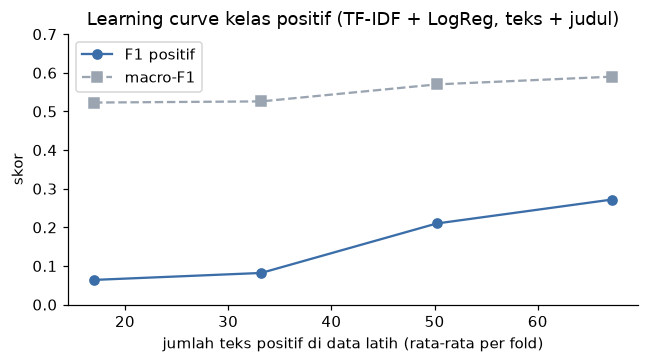

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


def fitur():
    teks = FeatureUnion([("kata", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                         ("huruf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True))])
    return ColumnTransformer([("teks", teks, "teks"),
                              ("judul", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "judul")],
                             transformer_weights={"teks": 1.0, "judul": 0.5})


X = pd.DataFrame({"teks": df.teks_lengkap.fillna(""), "judul": df.judul_lengkap.fillna("")})
prob_tfidf = np.zeros(len(y))
lc = []
for porsi in [0.25, 0.5, 0.75, 1.0]:
    for seed in ([0, 1, 2] if porsi < 1 else [0]):
        rng = np.random.default_rng(seed)
        for k in range(5):
            latih = np.where(fold != k)[0]
            pos = latih[y[latih] == "positif"]
            latih = np.setdiff1d(latih, rng.choice(pos, int(round(len(pos) * (1 - porsi))), replace=False))
            m = Pipeline([("f", fitur()), ("c", LogisticRegression(class_weight="balanced", C=3, max_iter=3000))]).fit(X.iloc[latih], y[latih])
            uji = fold == k
            if porsi == 1.0:
                prob_tfidf[uji] = m.predict_proba(X[uji])[:, list(m.classes_).index("positif")]
            s = f1_score(y[uji], m.predict(X[uji]), labels=LABEL, average=None, zero_division=0)
            lc.append({"porsi positif": porsi, "positif di data latih": int((y[latih] == "positif").sum()), "seed": seed,
                       "fold": k, "macro-F1": s.mean(), "F1 positif": s[2]})
lc = pd.DataFrame(lc)
kurva = lc.groupby("porsi positif").agg(**{"positif di data latih": ("positif di data latih", "mean"),
                                           "macro-F1": ("macro-F1", "mean"), "F1 positif": ("F1 positif", "mean")}).round(3)
kurva.to_csv(OUT / "learning_curve_positif.csv")
display(kurva)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(kurva["positif di data latih"], kurva["F1 positif"], "o-", color="#3b6ea8", label="F1 positif")
ax.plot(kurva["positif di data latih"], kurva["macro-F1"], "s--", color="#9aa5b1", label="macro-F1")
ax.set(xlabel="jumlah teks positif di data latih (rata-rata per fold)", ylabel="skor", ylim=(0, 0.7),
       title="Learning curve kelas positif (TF-IDF + LogReg, teks + judul)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "05_learning_curve_positif.png", bbox_inches="tight")
plt.show()

Dengan 17 teks positif di data latih, F1 positif hanya 0,064. Naik ke 0,082 dengan 33 teks, lalu melompat ke 0,210 dengan 50 teks dan 0,272 dengan 67 teks. Kurvanya belum mendatar di ujung kanan, jadi model belum jenuh. Kalau teks positif asli ditambah, F1 positif kemungkinan besar masih naik. Ini berbeda dengan parafrase, yang menambah jumlah tapi tidak menambah variasi.

### Dari mana data positif tambahan bisa didapat?

Ada 2.623 teks cadangan yang sudah lolos filter tapi belum dilabeli (`data/03_filtered/cadangan_belum_dilabel.csv`). Kalau diambil acak, porsi positifnya kira-kira sama dengan dataset (2,5%). Sel berikut mengecek apa yang terjadi kalau teks diurutkan dulu berdasarkan skor positif dari model: berapa banyak positif yang benar-benar ada di urutan teratas. Skor di sini adalah probabilitas positif dari TF-IDF + LogReg saat teks itu menjadi data uji, jadi tidak ada kebocoran.

In [9]:
urut = np.argsort(-prob_tfidf)
peringkat = pd.DataFrame([{"teks teratas": n, "positif": int((y[urut[:n]] == "positif").sum()),
                           "presisi": (y[urut[:n]] == "positif").mean(), "kalau acak": prev * n} for n in [50, 100, 200, 400]])
peringkat.to_csv(OUT / "peringkat_positif.csv", index=False)
peringkat.round(3)

,teks teratas,positif,presisi,kalau acak
0,50,17,0.340,1.262
1,100,26,0.260,2.523
2,200,38,0.190,5.047
3,400,49,0.122,10.093


Kalau teks diurutkan berdasarkan skor positif, 50 teks teratas berisi 17 positif (34%), 100 teratas berisi 26 (26%), dan 200 teratas berisi 38 (19%). Kalau diambil acak, 200 teks hanya berisi sekitar 5 positif. Dari sini saya menyarankan pelabelan terarah dari 2.623 teks cadangan, bukan scraping ulang: model mengurutkan teks cadangan, lalu teks teratas dilabeli dengan alur yang sama (3 AI, lalu 3 orang untuk teks yang tidak disepakati). Waktu itu saya memperkirakan 40 sampai 60 positif baru dari 300 teks.

Ada satu syarat. Teks dari pelabelan terarah sengaja dipilih yang condong positif, jadi tidak boleh masuk data uji atau statistik sentimen di notebook 06. Perlakuannya sama seperti jalur B, yaitu hanya menambah data latih. Hasil sebenarnya ada di bagian berikut.

### Hasil pelabelan terarah

Saran dari bagian sebelumnya sudah dijalankan (`labeling/terarah/`). Model mengurutkan teks cadangan, lalu 250 teks dengan skor positif tertinggi dan 50 teks acak sebagai pembanding dilabeli dengan alur yang sama seperti data utama: 3 annotator AI, teks yang tidak disepakati bulat dinilai 3 orang, dan kartu yang ketiganya beda diputus koordinator. Annotator tidak diberi tahu skor atau cara pilih teks. Teks positif yang bukan buzzer dan akunnya tidak ada di dataset final dipakai sebagai augmentasi **jalur B + terarah**, hanya di fold latih.

Sel pertama merangkum hasil pelabelannya. Sel kedua membandingkan langsung jalur B dengan jalur B + terarah di model dan input yang sama.

In [10]:
lt = pd.read_csv(D / "04_labeled" / "label_terarah.csv")
aug_t = pd.read_csv(D / "05_final" / "augmentasi_terarah.csv")
ring = (ROOT / "labeling" / "terarah" / "ringkasan_terarah.md").read_text(encoding="utf-8")
print("sumber label:", lt.sumber_label.value_counts().to_dict())
print("Fleiss' kappa review 3 orang, jumlah kartu:", re.search(r"Fleiss' kappa = ([0-9.]+).*? di (\d+) kartu", ring).groups())
print("positif dipakai untuk augmentasi:", len(aug_t), "| per cara pilih:", aug_t.cara_pilih.value_counts().to_dict())
pd.crosstab(lt.cara_pilih, lt.label.fillna("seri"), margins=True).assign(
    porsi_positif=lambda t: (t.positif / t.All).round(3))

sumber label: {'llm_bulat': 227, 'manusia_mayoritas': 66, 'manusia_koordinator': 7}
Fleiss' kappa review 3 orang, jumlah kartu: ('0.260', '73')
positif dipakai untuk augmentasi: 32 | per cara pilih: {'skor_tertinggi': 30, 'acak': 2}


label,negatif,netral,positif,tidak_relevan,All,porsi_positif
cara_pilih,,,,,,
acak,37,5,2,6,50,0.040
skor_tertinggi,151,54,33,12,250,0.132
All,188,59,35,18,300,0.117


In [11]:
baris = []
for (m, i), t in hasil[hasil.augmentasi == "jalur B + terarah"].groupby(["model", "input"], sort=False):
    b = hasil[(hasil.model == m) & (hasil.input == i) & (hasil.augmentasi == "jalur B")].sort_values("fold")
    if b.empty:
        continue
    t = t.sort_values("fold")
    d = t.macro_f1.values - b.macro_f1.values
    baris.append({"model": m, "input": i, "macro-F1 jalur B": round(b.macro_f1.mean(), 3),
                  "macro-F1 + terarah": round(t.macro_f1.mean(), 3), "Δ macro-F1": round(d.mean(), 3),
                  "fold membaik": f"{(d > 0).sum()}/5", "F1 positif jalur B": round(b.f1_positif.mean(), 3),
                  "F1 positif + terarah": round(t.f1_positif.mean(), 3),
                  "Δ F1 positif": round((t.f1_positif.values - b.f1_positif.values).mean(), 3)})
dampak_terarah = pd.DataFrame(baris)
dampak_terarah.to_csv(OUT / "dampak_terarah.csv", index=False)
dampak_terarah

,model,input,macro-F1 jalur B,macro-F1 + terarah,Δ macro-F1,fold membaik,F1 positif jalur B,F1 positif + terarah,Δ F1 positif
0,TF-IDF + LogReg,teks saja,0.551,0.561,0.009,3/5,0.269,0.293,0.024
1,TF-IDF + LogReg,teks + judul,0.589,0.603,0.015,4/5,0.266,0.313,0.047
2,IndoBERT fine-tune,teks + judul,0.614,0.616,0.001,2/5,0.325,0.352,0.028
3,IndoBERTweet fine-tune,teks + judul,0.597,0.609,0.012,2/5,0.295,0.323,0.028
4,IndoBERT embedding + LogReg,teks saja,0.523,0.507,-0.016,0/5,0.245,0.211,-0.034
5,IndoBERT embedding + LogReg,teks + judul,0.586,0.570,-0.016,1/5,0.309,0.275,-0.035
6,BiLSTM + attention,teks saja,0.514,0.498,-0.016,2/5,0.295,0.243,-0.052
7,BiLSTM + attention,teks + judul,0.512,0.505,-0.006,3/5,0.238,0.225,-0.013


Hasilnya di bawah perkiraan. Dari 250 teks dengan skor positif tertinggi, hanya 33 yang positif (13%), dan dari 50 teks acak ada 2 (4%). Totalnya 35 positif dari 300 teks, bukan 40 sampai 60. Presisinya juga lebih rendah dari peringkat di data berlabel (19% di 200 teratas). Dugaan saya, teks cadangan memang sisa yang tidak terpilih di sampel utama, dan 18 di antaranya ternyata tidak relevan. Walaupun begitu, pengurutan tetap sekitar 3 kali lebih efisien daripada sampel acak. Setelah 2 teks dibuang karena akunnya sudah ada di dataset final dan 1 teks dinilai buzzer, ada 32 teks positif baru untuk augmentasi.

Labelnya berasal dari 227 teks yang disepakati bulat 3 AI, 66 teks yang diputuskan mayoritas 3 orang, dan 7 kartu yang ketiga penilainya memilih label berbeda. Untuk 7 kartu ini koordinator memakai label mayoritas 3 AI, dan keputusannya dicatat di `labeling/terarah/review/koordinator.csv` supaya bisa diubah kalau tim tidak setuju. Fleiss' kappa di 73 kartu review adalah 0,260, setara dengan review utama (0,286). Kappa positif paling tinggi (0,549), sedangkan netral paling rendah (0,116).

Dampaknya ke model terbagi dua. TF-IDF dan model fine-tune terbantu: TF-IDF + LogReg teks + judul naik 0,015 (4 dari 5 fold) dengan F1 positif naik 0,047, IndoBERTweet naik 0,012, dan IndoBERT praktis sama (+0,001), tapi F1 positif-nya naik 0,028 dan AP positif naik dari 0,333 ke 0,383. Sebaliknya, model yang bobot BERT-nya dibekukan malah turun: IndoBERT embedding + LogReg turun 0,016 di kedua input, dan BiLSTM turun 0,006 sampai 0,016. Dugaan saya, teks terarah dipilih dari skor TF-IDF, jadi isinya condong ke kata yang memang sudah dikenali TF-IDF, sedangkan untuk model dengan representasi beku, 32 teks ini lebih menggeser batas kelas daripada menambah pola baru. Semua kenaikan ini masih di dalam standar deviasi antar fold, jadi terarah membantu sedikit, bukan lompatan besar.

XLM-RoBERTa tidak dilatih ulang dengan varian terarah. Model ini paling lemah di antara model fine-tune dan satu kernel butuh sekitar 1 jam GPU, jadi kuota Kaggle dipakai untuk IndoBERT dan IndoBERTweet saja.

## Lowercase di model BERT

Notebook 03 mencetak isi `do_lower_case` tokenizer saat dijalankan di Kaggle. Sel ini membaca hasilnya langsung dari log Kaggle, supaya jelas bahwa jawabannya berasal dari tokenizer, bukan dugaan.

In [12]:
for f in sorted((D / "07_transformer").glob("*.log")):
    log = f.read_text(encoding="utf-8")
    print(f.name)
    for pola in [r"do_lower_case di tokenizer: (\w+)", r"'BOIKOT RANS'\s+-\\u003e (\[[^\]]*\])"]:
        for m in re.findall(pola, log)[:1]:
            print("  ", m)

uas-nlp-raffi-indobert.log
   True
   ['bo', '##ikot', 'rans']
uas-nlp-raffi-indobertweet.log
   True
   ['boikot', 'ran', '##s']
uas-nlp-raffi-xlmr.log


Kedua tokenizer mencetak `do_lower_case` True. IndoBERTweet memecah "BOIKOT RANS" menjadi `['boikot', 'ran', '##s']`, dan IndoBERT menjadi `['bo', '##ikot', 'rans']`, sama persis dengan versi huruf kecilnya. Jadi untuk IndoBERTweet dan IndoBERT, teks di-lowercase atau tidak di preprocessing hasilnya sama, karena tokenizer tetap mengubahnya menjadi huruf kecil. Percobaan dengan dan tanpa lowercase tidak perlu dijalankan untuk dua model ini. Satu-satunya model yang membaca huruf kapital adalah XLM-RoBERTa (cased).

## Analisis kesalahan

Bagian ini memakai prediksi model terbaik untuk semua 5 fold uji (setiap teks diprediksi tepat sekali saat menjadi data uji). Langkahnya: confusion matrix, lalu akurasi per kelompok teks, lalu membaca contoh kesalahan dan mengelompokkannya.

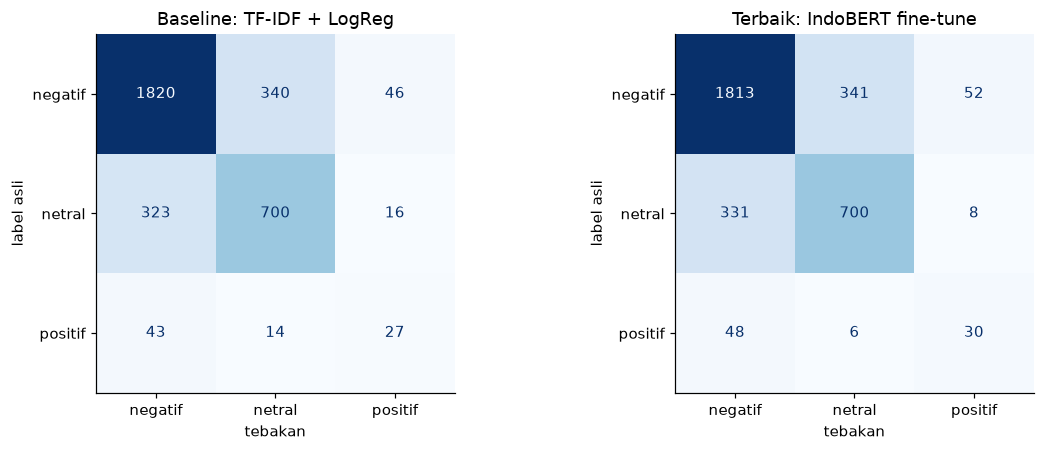

pred     negatif  netral  positif
label                            
negatif    0.822   0.155    0.024
netral     0.319   0.674    0.008
positif    0.571   0.071    0.357


In [13]:
df["pred"] = prediksi(top.model, top.input, top.augmentasi)
df["pred_base"] = prediksi(base.model, base.input, base.augmentasi)
df["benar"] = df.pred == df.label
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, kol, judul in [(axes[0], "pred_base", f"Baseline: {base.model}"), (axes[1], "pred", f"Terbaik: {top.model}")]:
    cm = confusion_matrix(df.label, df[kol], labels=LABEL)
    ConfusionMatrixDisplay(cm, display_labels=LABEL).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set(title=judul, xlabel="tebakan", ylabel="label asli")
plt.tight_layout()
plt.savefig(FIG / "05_confusion_matrix.png", bbox_inches="tight")
plt.show()
ct = pd.crosstab(df.label, df.pred, normalize="index").round(3)
ct.to_csv(OUT / "confusion_terbaik.csv")
print(ct)

Recall negatif 82,2%, netral 67,4%, dan positif 35,7%. Recall positif ini lebih tinggi dari model jalur B sebelumnya (27,4%), dan ini efek langsung dari teks positif terarah. Teks positif yang salah hampir semuanya ditebak negatif (57,1% dari semua teks positif), hanya 7,1% yang ditebak netral.

In [14]:
def per_kelompok(nama, kolom):
    t = df.groupby(kolom).agg(n=("benar", "size"), akurasi=("benar", "mean"),
                              macro_f1=("label", lambda s: f1_score(s, df.loc[s.index, "pred"], labels=LABEL,
                                                                    average="macro", zero_division=0)))
    return t.round(3).assign(kelompok=nama).reset_index().rename(columns={kolom: "nilai"})


df["panjang"] = pd.cut(df.text.str.split().str.len(), [0, 5, 15, 40, 1000], labels=["1-5 kata", "6-15", "16-40", "> 40"])
df["ada_target_lain"] = df.target_lain.fillna("").ne("")
kel = pd.concat([per_kelompok("platform", "platform"), per_kelompok("sarkasme", "sarkasme"),
           per_kelompok("butuh judul", "butuh_konteks"), per_kelompok("ada pihak lain yang dikritik", "ada_target_lain"),
           per_kelompok("panjang teks", "panjang"), per_kelompok("fase", "fase")])[["kelompok", "nilai", "n", "akurasi", "macro_f1"]]
kel.to_csv(OUT / "akurasi_per_kelompok.csv", index=False)
kel

,kelompok,nilai,n,akurasi,macro_f1
0,platform,instagram,867,0.807,0.585
1,platform,tiktok,488,0.775,0.636
2,platform,x,1266,0.711,0.536
3,platform,youtube,708,0.798,0.608
0,sarkasme,False,3172,0.760,0.616
1,sarkasme,True,157,0.841,0.510
0,butuh judul,False,1637,0.797,0.675
1,butuh judul,True,1692,0.732,0.530
0,ada pihak lain yang dikritik,False,2359,0.777,0.620
1,ada pihak lain yang dikritik,True,970,0.731,0.490


Model paling sering salah di teks yang juga mengkritik pihak lain (macro-F1 0,490 dibanding 0,620) dan teks yang ditandai butuh judul (0,530 dibanding 0,675). Teks lebih dari 40 kata juga lebih sulit (akurasi 66,7%, teks 1 sampai 5 kata 81,3%). Per platform, X paling rendah (macro-F1 0,536), kemungkinan karena separuh tweet tidak punya judul. Teks sarkasme akurasinya tinggi (84,1%) karena hampir semuanya negatif, tapi macro-F1-nya rendah (0,510). Fase pasca lebih sulit dari fase puncak (0,569 dibanding 0,647), karena di fase pasca topiknya melebar ke kontrak Rp14,7 miliar dan bisnis Raffi.

In [15]:
salah = df[~df.benar]
print("jumlah salah:", len(salah), f"({len(salah) / len(df):.1%})")
print(salah.groupby(["label", "pred"]).size().rename("n").sort_values(ascending=False).to_string())
print()
print("sub-kategori teks positif yang salah:")
sub_pos = df[df.label.eq("positif")].groupby("sub").benar.agg(["size", "mean"]).round(3)
sub_pos.to_csv(OUT / "positif_per_sub.csv")
salah.groupby(["label", "pred"]).size().rename("n").to_csv(OUT / "jenis_salah.csv")
print(sub_pos.to_string())

jumlah salah: 786 (23.6%)
label    pred   
negatif  netral     341
netral   negatif    331
negatif  positif     52
positif  negatif     48
netral   positif      8
positif  netral       6

sub-kategori teks positif yang salah:
           size   mean
sub                   
dukungan     22  0.773
informasi     1  0.000
lainnya       1  0.000
membela      42  0.167
simpati      16  0.375


Dari 786 teks yang salah (23,6%), dua kesalahan terbesar adalah negatif ditebak netral (341) dan netral ditebak negatif (331). Ini batas yang sama dengan yang paling sering diperdebatkan penilai manusia (kappa netral 0,219). Untuk teks positif, dukungan cukup sering benar (77,3%), tapi pembelaan hanya benar 16,7% (7 dari 42). Angka pembelaan ini naik dari 4 dari 42 di model jalur B, tapi tetap jenis teks positif yang paling sulit.

### Contoh kesalahan

Sel berikut menampilkan contoh acak dari tiga jenis kesalahan yang paling penting: positif yang ditebak negatif, netral yang ditebak negatif, dan negatif yang ditebak netral. Contoh ini saya baca satu per satu untuk mencari polanya.

In [16]:
for asli, tebak in [("positif", "negatif"), ("netral", "negatif"), ("negatif", "netral")]:
    s = df[(df.label == asli) & (df.pred == tebak)]
    print(f"\n{asli} ditebak {tebak} ({len(s)} teks):")
    display(s.sample(min(10, len(s)), random_state=5)[["text", "sub", "target_lain", "sarkasme"]])


positif ditebak negatif (48 teks):


,text,sub,target_lain,sarkasme
2039,@user @user Makanya persepsi itu jgn fomo. Konteks komentar gua cuma satu; nggak apple-to-apple. Kalo arah...,membela,NaN,False
2270,"Benar spt kt pribahasa..""10 kebaikkan akan kalah dengan 1 kesalahan/keburukkan"". Manusia mmng gudangnya sa...",membela,NaN,False
273,Herannya klen ngamuk sama raffi ahmad tapi gk ada yg ngamuk sama si zaskia mecca bela anak koruptor. Emang...,membela,NaN,False
1025,kerja namany itu proooo dunia gak ada gratisss fahammmmm,membela,NaN,False
1323,orang yg ngehujat raffi ahmad mungkin dia belum ketemu langsung sama raffi ahmad. belum tau sebaik dan seh...,membela,NaN,False
1929,@user Jangan menyebar fitnah. heran gue akun verified ini ‘ngejar engagement dengan cara2 yg sembarangan. ...,membela,NaN,False
243,"Hapus nih video bang, kalau gak gw laporin lu nyed",membela,NaN,False
3153,Sepertinya Raffi Ahmad memang sedang dijadikan tumbal oleh bos besarnya lewat deklarasi mahasiswa bayaran ...,simpati,pemerintah,False
244,netizen harusnya paham bedanya tamu undangan instansi sama peserta aksi massa,membela,NaN,False
3310,Sayang A Raffi karier yang AA bangun dari kecil rusak hanya demi ambisi 😊 mending jangan merapat kepemerin...,simpati,NaN,False



netral ditebak negatif (331 teks):


,text,sub,target_lain,sarkasme
1157,tahun lalu uya kuya dan syahroni yang ditumbalin. sekarang kayaknya giliran rafi ahmad yang jadi bumper ke...,lainnya,pemerintah,False
1485,"Kemaren sama Raffi Ahmad gampang banget dibuka bjir, malah disediain panggung segala, kok ini engga ya? 🤣🤣🤣",lainnya,polisi,False
3143,@user Sabar brooo...kalau nyari orang2 seperti itu cukup raffi ahmad saja yg gantiin,lainnya,NaN,False
2846,salut tepuk tangan buat Seniman yogyakarta... 😁,boikot,NaN,False
654,Bodo amiirrrr udahhh,lainnya,NaN,False
1224,"Kata gw buzerp itu tolol Kata anak gw,klo ga tolol ga bakal mau jd buzerp di saat Indonesia lg sakit gini ...",lainnya,mahasiswa_bayaran,False
2918,banyak uang ping pong ke sesama okmun pejabat di negara konoha,lainnya,pemerintah,False
3315,Laa illaaha illaa anta subhaanaka inni kuntuminadzolimiinn 😢😭😭 Yaa Allah yaa Rahman yaa Rahimm.. karuniaka...,NaN,NaN,False
1934,@user Artis kaya raffi ahmad dong bang aaaaaa,lainnya,NaN,False
1186,"Rans festival sepi setelah beberapa pihak memboikot raffi ahmad, beberapa artis juga lebih memilih mundur,...",pertanyaan,NaN,False



negatif ditebak netral (341 teks):


,text,sub,target_lain,sarkasme
973,ternyata aku yg kismin ini bisa2nya membiayaiin cipung 😭😭😭 aku ajh jualan baju bekas sehari cuma dpat 50 r...,sindiran,NaN,True
2942,"@user cabang nct banyak si emang, pada pernah ke rumah raffi ahmad sama sarwendah. kalo unit dream mah per...",sindiran,NaN,False
1276,"@user Waahh wes, bangun usaha seko nol dadi sukses dan rsme ngene mah calon kukut kyo rafi ahmad mergo man...",sindiran,NaN,False
2369,RAPI CEBOKER AKUD WOWO FUFUFAFA 😂😂😂😂,hinaan,NaN,False
342,Terus viralkan & budayakan boikotnya ketiap penjuru,boikot,NaN,False
1045,3M buat karhutla kata Desta Raffi : masih ada 11M brooo 🤣🤣🤣,sindiran,NaN,False
2619,Harus di proses hukum itu orang...siapah ajah mau dia siapah harus di proses secara hukum. Kalau tidak sam...,kritik,NaN,False
1349,@user Didunia ini gak ada yg abadi. Sepandai2 raffi ahmad akhirnya jatuh juga 😜,sindiran,NaN,False
1548,@user Udah jelas KKN ini. Segera cekal rafi ahmad dan tangkap.,kritik,NaN,False
998,sampe ada ATM khusus d rumahnya wkwkkwkwk,sindiran,NaN,False


Contoh positif yang ditebak negatif memperlihatkan polanya. Hampir semuanya pembelaan yang ditulis dengan nada kesal ke pengkritik Raffi, misalnya "Herannya klen ngamuk sama raffi ahmad tapi gk ada yg ngamuk sama si zaskia mecca...", "kerja namany itu proooo dunia gak ada gratisss fahammmmm", dan "netizen harusnya paham bedanya tamu undangan instansi sama peserta aksi massa". Model membaca nadanya, bukan sasarannya.

Contoh netral yang ditebak negatif ada dua jenis: berita yang menyebut Raffi bersama kata yang terdengar negatif ("Rans festival sepi setelah beberapa pihak memboikot raffi ahmad..."), dan kemarahan ke pihak lain, misalnya ke pemerintah ("tahun lalu uya kuya dan syahroni yang ditumbalin...") atau ke buzzer. Contoh negatif yang ditebak netral kebanyakan sindiran yang butuh pengetahuan kasus, seperti "3M buat karhutla kata Desta Raffi : masih ada 11M brooo 🤣🤣🤣" dan "Didunia ini gak ada yg abadi. Sepandai2 raffi ahmad akhirnya jatuh juga 😜". Ada juga kritik yang cukup jelas tapi tetap lolos, misalnya "Udah jelas KKN ini. Segera cekal rafi ahmad dan tangkap."

In [17]:
keduanya = (df.pred != df.label) & (df.pred_base != df.label)
hanya_base = (df.pred == df.label) & (df.pred_base != df.label)
hanya_top = (df.pred != df.label) & (df.pred_base == df.label)
print("salah di kedua model         :", int(keduanya.sum()))
print("baseline salah, terbaik benar:", int(hanya_base.sum()))
print("baseline benar, terbaik salah:", int(hanya_top.sum()))
print()
print("contoh yang diperbaiki model terbaik:")
display(df[hanya_base & df.label.ne("negatif")].sample(8, random_state=2)[["text", "label", "pred_base", "pred"]])

salah di kedua model         : 428
baseline salah, terbaik benar: 354
baseline benar, terbaik salah: 358

contoh yang diperbaiki model terbaik:


,text,label,pred_base,pred
1750,@user Kayak tukang bangunan nyalahkan mandor. Btw Ini rafi ahmad reaksinya gmna ya 🤣🤣,netral,negatif,netral
1880,@user dipatok rafi ahmad,netral,negatif,netral
3092,things we should NOT give a fuck: - penyadapan prabowo - ijazah jokowi - klarifikasi dari raffi ahmad - ke...,netral,negatif,netral
262,Biarinlah kalian sibuk demo disana. Gak ngaruh ke kami. (kata orang orang yang dulunya kaum 58) #Indonesia...,netral,negatif,netral
3091,Gara2 video ini aktor raffi ahmad di bully netizen sebelah 😂,netral,negatif,netral
156,Astaghfirullaah. Mirisnya negeriku 😢,netral,negatif,netral
2779,"Inget... kalau ada yg mau komen jangan ke gue, langsung aja ke @user",netral,negatif,netral
1440,oohhh ini mamah ny Raffi Ahmad?,netral,negatif,netral


Ada 428 teks yang salah di kedua model. Sebanyak 354 teks salah di baseline tapi benar di model terbaik, dan 358 sebaliknya. Jadi kedua model salah di teks yang cukup berbeda, dan jumlah perbaikannya hampir sama dengan jumlah kemundurannya, sejalan dengan selisih macro-F1 yang kecil. Contoh yang diperbaiki model terbaik hampir semuanya teks netral yang ditebak negatif oleh TF-IDF karena memuat kata seperti "bully", "miris", atau "nyalahkan", misalnya "Gara2 video ini aktor raffi ahmad di bully netizen sebelah 😂" dan "Astaghfirullaah. Mirisnya negeriku 😢". TF-IDF hanya menghitung kata, sedangkan IndoBERT bisa membaca bahwa kata negatif itu bukan sikap penulis terhadap Raffi.

## Jejak saran dosen

Tabel ini merangkum setiap saran dari konsultasi dosen, apa yang dikerjakan, dan di berkas mana hasilnya bisa dicek.

| saran dosen | yang dikerjakan | hasil | bukti |
|---|---|---|---|
| Gerbang filter jangan overklaim | Aturan otomatis hanya menandai kandidat, setiap kandidat dibaca manual | 61 teks diselamatkan | `data/03_filtered/audit/keputusan_manual.csv`, notebook 01 |
| Relevansi dan buzzer: siapa yang memutuskan | Relevansi: kata kunci menandai, manusia memutuskan, lalu `tidak_relevan` dinilai 3 AI dan 3 orang. Buzzer: aturan keras dan skor poin, zona batas diputuskan manusia | 14 buzzer dan 182 tidak relevan dikeluarkan | `dokumentasi_data.md` bagian 2, `data/05_final/laporan_kesiapan.md` |
| Label dinilai 3 orang, hitung Fleiss' kappa | Semua teks yang tidak disepakati 3 AI dinilai 3 orang, termasuk teks pelabelan terarah | 881 kartu, kappa 0,286; terarah 73 kartu, kappa 0,260 | `labeling/review/3lapis/ringkasan_kappa.md`, `labeling/terarah/ringkasan_terarah.md` |
| Hapus target biner | Semua model 3 kelas | tidak ada target biner | notebook 02 sampai 05 |
| Sampel positif dari akun Raffi, augmentasi | Jalur B, parafrase, dan pelabelan terarah, hanya di fold latih, diuji per varian | jalur B membantu 9/9, parafrase 1/9, terarah 5/8 | bagian dampak augmentasi dan hasil pelabelan terarah |
| BERT tanpa lowercase | Teks dikirim apa adanya, emoji jadi kata Indonesia | IndoBERTweet dan IndoBERT uncased, jadi tidak berpengaruh | bagian lowercase di atas, log Kaggle |
| IndoBERT embedding + LogReg, model kontekstual | Embedding + LogReg, BiLSTM, fine-tune 3 model | fine-tune terbaik (0,616) | notebook 03 dan 04 |
| F1 positif rendah | Ensemble, ambang, learning curve, peringkat cadangan, pelabelan terarah | terarah dan ensemble membantu sedikit, ambang tidak | bagian strategi dan hasil pelabelan terarah |
| Analisis kesalahan | Confusion matrix, per kelompok, contoh | pembelaan bernada marah paling sering salah (hanya 16,7% benar) | bagian analisis kesalahan |

## Kesimpulan

- Model tunggal terbaik adalah fine-tune IndoBERT dengan input teks + judul dan augmentasi jalur B + terarah (macro-F1 0,616), praktis seri dengan IndoBERT jalur B (0,614) dan IndoBERTweet jalur B + terarah (0,609). Ensemble IndoBERT + IndoBERTweet dengan augmentasi yang sama paling tinggi (0,628, AP positif 0,381). XLM-RoBERTa lebih lemah (0,580) dan tidak menambah apa-apa kalau ikut di-ensemble.
- Jarak dengan TF-IDF + LogReg terbaik (0,603) kecil dan model terbaik hanya unggul di 3 dari 5 fold.
- Judul adalah tambahan input yang paling konsisten membantu.
- Augmentasi jalur B membantu di semua konfigurasi, sedangkan parafrase back-translation hanya membantu XLM-RoBERTa, model yang paling lemah.
- Pelabelan terarah menghasilkan 35 positif dari 300 teks (13% di teks skor tertinggi, 4% di teks acak) dan 32 dipakai sebagai augmentasi. Hasilnya menaikkan F1 positif dan AP model fine-tune dan TF-IDF, tapi menurunkan model dengan representasi beku, dan semua perubahannya masih di dalam variasi antar fold. Jadi terarah membantu sedikit, bukan lompatan besar.
- Menggeser ambang kelas positif tidak membantu secara konsisten.
- F1 positif sekitar 0,35 masih rendah, tapi sekitar 15 kali tebakan acak kalau dilihat dari AP. Learning curve belum jenuh, jadi menambah teks positif asli tetap langkah paling menjanjikan, hanya saja teks cadangan yang tersisa ternyata tidak sekaya perkiraan awal.
- Kesalahan utama model ada di pembelaan yang ditulis dengan nada marah ke pengkritik Raffi, dan di batas negatif dan netral yang juga diperdebatkan penilai manusia.